[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/07_language-models.ipynb)

*Deep Learning & LLMs · Notebook 7 of 10*

# Language Models

How an LLM predicts and generates: bigram models by hand, perplexity, the shifted cross-entropy loss, temperature, top-k, top-p, beam search, repetition penalties and the KV cache.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** An LLM is autocomplete taken very far: predict one token, add it, repeat.

**What interviewers really test here:** Shifted loss, temperature, top-k vs top-p, beam search and the KV cache.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. A language model predicts the next token *(Basics)*
- [ ] 2. Smoothing, log probabilities and perplexity *(Basics)*
- [ ] 3. From counting to a neural network *(Core)*
- [ ] 4. How an LLM is trained *(Core)*
- [ ] 5. Temperature: how bold to be *(Core)*
- [ ] 6. Top-k and top-p *(Core)*
- [ ] 7. Greedy, beam search and stopping *(Core)*
- [ ] 8. Generating quickly: the KV cache *(Advanced)*
- [ ] 9. From raw model to helpful assistant *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Decoding methods

| Method | Rule | Best for |
| --- | --- | --- |
| Greedy | top token | deterministic, short outputs |
| Beam search | keep the best few paths | translation, speech |
| Temperature | softmax(logits / T) | controlling variety |
| Top-k | keep k tokens | removing the tail |
| Top-p | keep up to total probability p | adapting to certainty |

### Numbers worth remembering

| Quantity | Value |
| --- | --- |
| Initial loss | ln V |
| Perplexity of a uniform guess | V |
| Cost without KV cache | N·P + N(N−1)/2 |
| Cost with KV cache | P + N − 1 |
| Entropy of a uniform guess | ln V |

### Common bugs

- Forgetting to shift targets: the model learns to copy its input and reports a nearly-zero loss.
- Missing the causal mask, with the same symptom.
- A loss far from ln V at the start, usually a sign of a data or label bug.
- Comparing perplexity across different tokenisers.
- Padding counted in the loss.

---
# Part 2: Lessons, step by step

## Lesson 1: A language model predicts the next token

*Level: Basics*

Every language model, from a tiny one to the largest, does one thing: **given the tokens so far, return a probability for each possible next token**. Long answers come from doing this repeatedly.



**The smallest possible model** looks only at the previous word. Corpus: the cat sat the cat ran the dog ran.



| Previous | Next: count | Probabilities |
| --- | --- | --- |
| the | cat: 2, dog: 1 | cat 2/3 = 0.667, dog 1/3 = 0.333 |
| cat | sat: 1, ran: 1 | 0.5 each |
| sat | the: 1 | the 1.0 |
| ran | the: 1 | the 1.0 |
| dog | ran: 1 | ran 1.0 |



That table *is* the model: it was "trained" by counting. To generate:



1. Look at the last token.
2. Choose the next one using its row of probabilities.
3. Add it and repeat.



The demo trains this on a slightly longer text and generates from it. The output has the right local word pairs, yet makes little overall sense, because a single word of context can't carry meaning across a sentence. Everything else in this course, from embeddings to attention, exists to use more context better.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def bigram_generates():
    text = "the cat sat on the mat the dog sat on the log the cat ran to the dog the dog ran to the mat".split()
    table = {}
    for a, b in zip(text, text[1:]):
        table.setdefault(a, []).append(b)
    rng = np.random.default_rng(1)
    word, out = "the", ["the"]
    for _ in range(14):
        word = str(rng.choice(table[word]))
        out.append(word)
    print(" ".join(out))


bigram_generates()

the log the cat ran to the mat the dog ran to the dog the


**✏️ Your turn:** you now have what you need for [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 2: Smoothing, log probabilities and perplexity

*Level: Basics*

**Problem 1: zero counts.** "the ran" never appeared, so its probability is 0, and any sentence containing it scores 0. With **add-k smoothing** you pretend everything happened k extra times:



**P(next | prev) = (count + k) / (count of prev + k·V)**



With V = 5 distinct words and k = 1: P(ran | the) = (0 + 1) / (3 + 5) = **0.125**, up from 0.



Another option is **backoff**: when a pair is unseen, use a discounted single-word estimate. "dog cat" is unseen, and "cat" is 2 of 9 tokens, so the score is 0.4 × 2/9 = **0.0889**.



**Problem 2: tiny numbers.** Multiply 0.1 by itself 4 times and you get 0.0001. After a few hundred tokens, a computer rounds the product to exactly 0. So add logs instead: 4 × ln 0.1 = **−9.2103**.



**How good is a model?** **Perplexity** = exp(average negative log probability of the true tokens). It reads as "the model is as unsure as if choosing between this many equally likely options":



| Probabilities given to the true tokens | Calculation | Perplexity |
| --- | --- | --- |
| 1, 1 | exp(0) | 1: always certain and right |
| 0.25, 0.25, 0.25 | exp(1.3863) | 4: like choosing among 4 |
| 0.5, 0.125 | exp((0.693 + 2.079) / 2) | 4: same average uncertainty |



A uniform guess over a vocabulary of size V gives a perplexity of exactly V. That's a useful sanity check for an untrained model. It's only comparable between models using the same tokeniser and test text.

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q15](#q15), [Q11](#q11), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: From counting to a neural network

*Level: Core*

The same bigram model can be learned rather than counted. Give each previous word a row of **logits**, one per possible next word. Softmax turns these into probabilities, and gradient descent adjusts them.



The gradient of cross-entropy has a neat form. For one example:



**new logits = logits + lr · (one\_hot(target) − probs)**



Two next words, logits 0 and 0, true target 0, lr = 1. Then probs = (0.5, 0.5), so:



- Update for target: 1 − 0.5 = +0.5
- Update for other: 0 − 0.5 = −0.5
- New logits: **(0.5, −0.5)**



Read that as "more of the right answer, less of whatever you were wrongly predicting". A confident correct prediction barely changes anything, and a confident wrong one changes a lot.



The chart trains on the demo's text. The loss starts at ln 9 = 2.197, since there are 9 words and all begin equally likely. It falls towards 0.640, the loss of the exact counting table, reaching 0.648 after 300 steps. So training has rediscovered what counting gave directly.



**So why bother with a network?** A table can't scale. With 50,000 tokens and a context of just 5, there would be 50,000⁵ rows. A neural network shares its weights, so it can generalise to contexts it has never seen. That's the actual leap from n-grams to LLMs.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

start: 2.197 end: 0.648 counting: 0.64


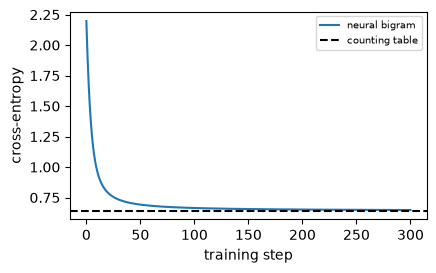

In [3]:
def neural_bigram_training():
    text = ("the cat sat on the mat the dog sat on the log the cat ran to the dog the dog ran to the mat " * 6).split()
    vocab = sorted(set(text))
    ids = np.array([vocab.index(w) for w in text])
    x, y = ids[:-1], ids[1:]
    V = len(vocab)
    counts = np.zeros((V, V))
    np.add.at(counts, (x, y), 1)
    exact = -np.log((counts / counts.sum(axis=1, keepdims=True))[x, y]).mean()
    logits, curve = np.zeros((V, V)), []
    for _ in range(301):
        e = np.exp(logits - logits.max(axis=1, keepdims=True))
        p = e / e.sum(axis=1, keepdims=True)
        curve.append(-np.log(p[x, y]).mean())
        grad = np.zeros_like(logits)
        np.add.at(grad, (x, y), 1)
        np.add.at(grad, x, -p[x])
        logits += 5 * grad / len(x)
    print("start:", round(curve[0], 3), "end:", round(curve[-1], 3), "counting:", round(exact, 3))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(curve, label="neural bigram")
    ax.axhline(exact, color="black", linestyle="--", label="counting table")
    ax.set_xlabel("training step")
    ax.set_ylabel("cross-entropy")
    ax.legend(fontsize=7)


neural_bigram_training()

**✏️ Your turn:** you now have what you need for [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 4: How an LLM is trained

*Level: Core*

The training recipe for a large model is surprisingly close to this. First, cut windows from a huge text:



```python
data = [10, 11, 12, 13, 14, 15, 16, 17, 18, 19], block = 3, offsets = [0, 5]
x = [[10, 11, 12], [15, 16, 17]]
y = [[11, 12, 13], [16, 17, 18]]
```



The model outputs a row of logits per position, and the loss is the average cross-entropy against y. Every position is a prediction: seeing 10, predict 11; seeing 10, 11, predict 12; and so on. The causal mask from the last topic is what makes this fair.



**The loss by hand.** Logits [2, 0, 0], target 0: e² / (e² + 1 + 1) = 7.389 / 9.389 = 0.787, and −ln 0.787 = 0.2395. Logits [0, 1, 0], target 1: e / (e + 2) = 0.576, and −ln 0.576 = 0.5514. Mean: **0.3955**.



**Sanity check:** an untrained model should start near ln V. With 4 tokens and equal logits: ln 4 = **1.3863**. If your loss starts far from this, look for a bug before training.



**Padding:** by convention, a target of −100 means "ignore". For logits [2, 0], [0, 3], [9, 0] and targets 0, 1, −100, only the first two count: (0.1269 + 0.0486) / 2 = **0.0878**.



```python
logits = model(x)                                    # (N, T, vocab)
loss = F.cross_entropy(logits.reshape(-1, vocab), y.reshape(-1), ignore_index=-100)
```



The largest models apply this to enormous amounts of text with thousands of GPUs. That's a real engineering challenge, but the objective is this same line.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q12](#q12), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 5: Temperature: how bold to be

*Level: Core*

Once the model gives logits, you decide how to choose. **Temperature** divides the logits before softmax:



**probs = softmax(logits / T)**



With logits 2, 1, 0:



| T | Logits ÷ T | Probabilities | Behaviour |
| --- | --- | --- | --- |
| 0.5 | 4, 2, 0 | 0.867, 0.117, 0.016 | focused, predictable |
| 1 | 2, 1, 0 | 0.665, 0.245, 0.090 | as the model learned |
| 2 | 1, 0.5, 0 | 0.506, 0.307, 0.186 | varied, riskier |



As T approaches 0, it becomes "always take the top token". As T grows, it approaches a uniform random choice. Dividing doesn't reorder tokens; it only changes how sharply the probabilities separate.



**Entropy** measures the spread: −Σ p·ln p. It's 0 for (1, 0, 0), 0.693 for (0.5, 0.5), and 1.386 for four equal options.



**Sampling itself is simple.** Draw a random u in [0, 1), and walk along the running total. For probabilities 0.5, 0.3, 0.2 the running total is 0.5, 0.8, 1.0, so u = 0.1 picks token 0, u = 0.6 picks token 1 and u = 0.95 picks token 2.



**In real APIs:** not every model offers these controls. Recent Claude models reject non-default `temperature`, `top_p` and `top_k` values, so check the docs for the model you're using. It's still essential to understand them, for running your own models and reading research.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

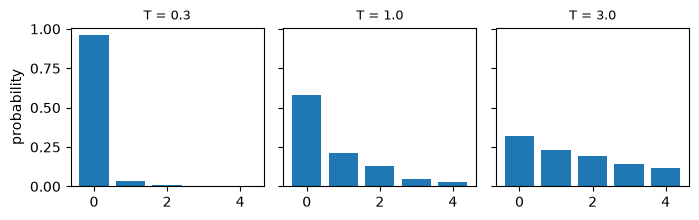

In [4]:
def temperature_chart():
    logits = np.array([3.0, 2.0, 1.5, 0.5, 0.0])
    fig, axes = plt.subplots(1, 3, figsize=(7, 2.3), sharey=True)
    for ax, T in zip(axes, [0.3, 1.0, 3.0]):
        e = np.exp(logits / T)
        ax.bar(range(5), e / e.sum())
        ax.set_title(f"T = {T}", fontsize=9)
    axes[0].set_ylabel("probability")
    fig.tight_layout()


temperature_chart()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q10](#q10), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 6: Top-k and top-p

*Level: Core*

Temperature keeps every token possible, so sometimes an absurd one gets chosen. Filtering removes the unlikely tail before sampling.



**Top-k** keeps a fixed number. With probabilities 0.4, 0.3, 0.2, 0.1 and k = 2: keep 0.4 and 0.3, total 0.7. Rescale: 0.4/0.7 = **0.5714** and 0.3/0.7 = **0.4286**.



**Top-p**, or nucleus sampling, keeps however many are needed to reach a total probability p, which adapts to the model's certainty:



| Probabilities | p | Added up | Kept | After rescaling |
| --- | --- | --- | --- | --- |
| 0.5, 0.3, 0.15, 0.05 | 0.75 | 0.5, then 0.8 ≥ 0.75 | 2 tokens | 0.625, 0.375 |
| 0.9, 0.05, 0.05 | 0.5 | 0.9 ≥ 0.5 | 1 token | 1.0 |



The same p keeps one token when the model is sure, and more when it's unsure. A fixed k can't do that, which is why top-p is often preferred.



The usual order is: repetition penalty, then temperature, then top-k or top-p, then sample.



**Repetition penalty:** without it, models can loop. For tokens already used, divide a positive logit by the penalty, and multiply a negative one by it. Either way the token gets less likely. With penalty 1.5: logit 2 → 1.3333 and logit −1 → −1.5. Use it gently, as some repetition is correct: names and "the" need repeating.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q16](#q16), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 7: Greedy, beam search and stopping

*Level: Core*

**Greedy** always takes the top token. It's simple, but the locally best step can lead somewhere poor:



| From | Options |
| --- | --- |
| s | x: 0.6, y: 0.4 |
| x | a: 0.5, b: 0.5 |
| y | c: 0.9, d: 0.1 |



- Greedy: s → x (0.6), x → a (0.5). Probability = **0.30**.
- Best overall: s → y (0.4), y → c (0.9). Probability = **0.36**.



Greedy rejected y at the first step because 0.4 &lt; 0.6, and never saw that y leads to a strong continuation.



**Beam search** keeps the best few candidates at every step. With width 2, it extends both x and y:



| Candidates after step 2 | Probability |
| --- | --- |
| s y c | **0.36** |
| s x a | 0.30 |
| s x b | 0.30 |
| s y d | 0.04 |



Trying every path takes Vˢᵗᵉᵖˢ work. With V = 50,000 and only 10 steps, that's unthinkable. A beam needs just width × V per step.



Beam search suits tasks with one right answer, such as translation or speech recognition. In open-ended writing, the highest-probability text tends to be bland and repetitive, so chat models usually sample instead.



**Stopping** happens when one of these occurs: the model produces its end token, the token limit is reached, or the text matches a **stop sequence**. "Answer: 42\\nUser: next" with stop "User:" returns "Answer: 42\\n".

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q20](#q20), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 8: Generating quickly: the KV cache

*Level: Advanced*

To generate a token, the model needs attention over all previous tokens. A naive loop re-runs everything each time:



| Step | Without a cache | With a cache |
| --- | --- | --- |
| 1 | 100 | 100 |
| 2 | 101 | 1 |
| 3 | 102 | 1 |
| … | … | … |



For a 100-token prompt and 50 new tokens, without a cache that's 50·100 + (50·49)/2 = **6,225** positions. With a cache it's 100 + 49 = **149**, about 42 times fewer.



**Why does this work?** Thanks to the causal mask, a token's output depends only on earlier tokens, so old keys and values never change. The model saves them per layer, and each new token computes only its own.



The price is memory, which grows with sequence length and has to be kept for each user. This is why long context costs money even when the model isn't generating much, and it's the mechanism behind **prompt caching** in the next topic: a provider reuses the work for a prefix it has already processed.



**Context windows:** a model has a maximum length, and past it something must go. With window 3 and tokens 1, 2, 3, then 4, 5: it sees [2, 3, 4], then [3, 4, 5]. Note that this forgets the *oldest* tokens, including possibly your instructions, so applications manage this deliberately.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

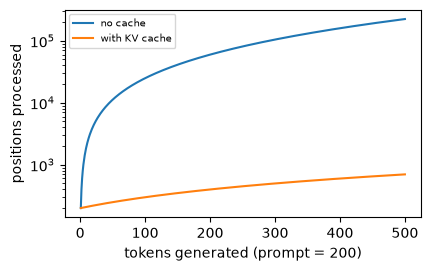

In [5]:
def kv_cache_chart():
    N = np.arange(1, 501)
    P = 200
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(N, N * P + N * (N - 1) / 2, label="no cache")
    ax.plot(N, P + N - 1, label="with KV cache")
    ax.set_yscale("log")
    ax.set_xlabel("tokens generated (prompt = 200)")
    ax.set_ylabel("positions processed")
    ax.legend(fontsize=7)


kv_cache_chart()

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 9: From raw model to helpful assistant

*Level: Advanced*

A model that only predicts the next token continues text; it doesn't answer. Ask a raw model "What is the capital of France?" and it may produce more quiz questions, since that's what often follows on the web. Getting to an assistant takes further stages:



| Stage | Data | What it adds |
| --- | --- | --- |
| Pre-training | a very large body of text | language and knowledge |
| Supervised fine-tuning | example conversations | answering in the assistant format |
| Preference training | which of two responses is better | helpfulness and safer behaviour |



**Limits that follow from how it works:**



- **Plausible isn't the same as true.** A model picks likely continuations, so it can state wrong things confidently. That's why you'd give it sources (RAG) and check output.
- **Knowledge has a date.** It only knows its training data, unless given tools.
- **Random output.** The same prompt can give different answers, which affects how you test.
- **Tokens, not letters.** Counting characters is harder than it looks.



Knowing what's actually going on makes you a better LLM engineer: you stop expecting magic, and you'd design for these limits. That's the next three topics.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Bigram Counts

🟢 Warm-up · *What follows what*

Return {previous: {next: count}} with both levels in sorted key order.

**Examples**

- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran']` → `{'cat': {'ran': 1, 'sat': 1}, 'dog': {'ran': 1}, 'ran': {'the': 1}, 'sat': {'the': 1}, 'the': {'cat': 2, 'dog': 1}}`

In [ ]:
def bigram_counts(tokens):
    """
    Return {previous: {next: count}} with both levels in sorted key order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bigram_counts, [
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'],), {'cat': {'ran': 1, 'sat': 1}, 'dog': {'ran': 1}, 'ran': {'the': 1}, 'sat': {'the': 1}, 'the': {'cat': 2, 'dog': 1}}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested dictionaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter(zip(t, t[1:]))`, then reshape.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested dictionaries.

```python
def bigram_counts(tokens):
    table = {}
    for a, b in zip(tokens, tokens[1:]):
        if a not in table:
            table[a] = {}
        table[a][b] = table[a].get(b, 0) + 1
    return {a: dict(sorted(table[a].items())) for a in sorted(table)}
```

**Cost:** O(n log n) time, O(pairs) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter(zip(t, t[1:]))`, then reshape.

```python
def bigram_counts(tokens):
    from collections import Counter
    out = {}
    for (a, b), c in sorted(Counter(zip(tokens, tokens[1:])).items()):
        out.setdefault(a, {})[b] = c
    return out
```

**Cost:** O(n log n) time, O(pairs) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested dictionaries. That costs O(n log n) time and O(pairs) space."

"I can do better: `Counter(zip(t, t[1:]))`, then reshape. That's O(n log n) time and O(pairs) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/bigram-counts)

<a id="q2"></a>
### Q2. Bigram Probability With Smoothing

🟢 Warm-up · *Unseen pairs aren't impossible*

Return (count(prev, next) + k) / (count(prev as a previous word) + k·V), where V is the number of distinct tokens. Round to 4 decimals.

**Examples**

- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], prev = 'the', next_ = 'cat', k = 0` → `0.6667`
- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], prev = 'the', next_ = 'ran', k = 0` → `0.0`
- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], prev = 'the', next_ = 'ran', k = 1` → `0.125`

In [ ]:
def bigram_prob(tokens, prev, next_, k):
    """
    Return (count(prev, next) + k) / (count(prev as a previous word) + k·V),
    where V is the number of distinct tokens. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bigram_prob, [
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], 'the', 'cat', 0), 0.6667),
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], 'the', 'ran', 0), 0.0),
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], 'the', 'ran', 1), 0.125),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count pairs in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy comparisons on arrays of neighbours.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count pairs in a loop.

```python
def bigram_prob(tokens, prev, next_, k):
    pair = sum(1 for a, b in zip(tokens, tokens[1:]) if a == prev and b == next_)
    total = sum(1 for a in tokens[:-1] if a == prev)
    return round((pair + k) / (total + k * len(set(tokens))), 4)
```

**Cost:** O(n) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy comparisons on arrays of neighbours.

```python
def bigram_prob(tokens, prev, next_, k):
    t = np.array(tokens)
    first = t[:-1] == prev
    return round(float((first & (t[1:] == next_)).sum() + k) / (first.sum() + k * len(set(tokens))), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count pairs in a loop. That costs O(n) time and O(V) space."

"I can do better: NumPy comparisons on arrays of neighbours. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/bigram-probability-with-smoothing)

<a id="q3"></a>
### Q3. Perplexity

🟢 Warm-up · *The effective number of choices*

Perplexity = exp(average negative log probability of the true tokens). Round to 4 decimals.

**Examples**

- `probs = [0.25, 0.25, 0.25]` → `4.0`
- `probs = [0.5, 0.125]` → `4.0`
- `probs = [1.0, 1.0]` → `1.0`

In [ ]:
def perplexity(probs):
    """
    Perplexity = exp(average negative log probability of the true tokens). Round
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(perplexity, [
    (([0.25, 0.25, 0.25],), 4.0),
    (([0.5, 0.125],), 4.0),
    (([1.0, 1.0],), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average in a loop, then `math.exp`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.exp(-np.log(p).mean())`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Average in a loop, then `math.exp`.

```python
def perplexity(probs):
    total = 0.0
    for p in probs:
        total -= math.log(p)
    return round(math.exp(total / len(probs)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.exp(-np.log(p).mean())`.

```python
def perplexity(probs):
    return round(float(np.exp(-np.log(probs).mean())), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average in a loop, then `math.exp`. That costs O(n) time and O(1) space."

"I can do better: `np.exp(-np.log(p).mean())`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/perplexity)

<a id="q4"></a>
### Q4. Make a Training Batch

🟢 Warm-up · *Random windows from a long text*

Given token ids, start offsets and block size, return (x, y), where y is x shifted by one.

**Examples**

- `data = [10, 11, 12, 13, 14, 15, 16, 17, 18, 19], offsets = [0, 5], block = 3` → `([[10, 11, 12], [15, 16, 17]], [[11, 12, 13], [16, 17, 18]])`

In [ ]:
def get_batch(data, offsets, block):
    """
    Given token ids, start offsets and block size, return (x, y), where y is x
    shifted by one.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(get_batch, [
    (([10, 11, 12, 13, 14, 15, 16, 17, 18, 19], [0, 5], 3), ([[10, 11, 12], [15, 16, 17]], [[11, 12, 13], [16, 17, 18]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slice in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Index an array with a broadcast grid.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Slice in a loop.

```python
def get_batch(data, offsets, block):
    x = [data[i:i + block] for i in offsets]
    y = [data[i + 1:i + block + 1] for i in offsets]
    return (x, y)
```

**Cost:** O(n·b) time, O(n·b) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Index an array with a broadcast grid.

```python
def get_batch(data, offsets, block):
    d = np.array(data)
    grid = np.array(offsets)[:, None] + np.arange(block)
    return (d[grid], d[grid + 1])
```

**Cost:** O(n·b) time, O(n·b) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slice in a loop. That costs O(n·b) time and O(n·b) space."

"I can do better: Index an array with a broadcast grid. That's O(n·b) time and O(n·b) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/make-a-training-batch)

<a id="q5"></a>
### Q5. Temperature

🟢 Warm-up · *Cautious or adventurous*

Return softmax(logits / T), rounded to 4 decimals.

**Examples**

- `logits = [2.0, 1.0, 0.0], T = 1.0` → `[0.6652, 0.2447, 0.09]`
- `logits = [2.0, 1.0, 0.0], T = 0.5` → `[0.8668, 0.1173, 0.0159]`
- `logits = [2.0, 1.0, 0.0], T = 2.0` → `[0.5065, 0.3072, 0.1863]`

In [ ]:
def with_temperature(logits, T):
    """
    Return softmax(logits / T), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(with_temperature, [
    (([2.0, 1.0, 0.0], 1.0), [0.6652, 0.2447, 0.09]),
    (([2.0, 1.0, 0.0], 0.5), [0.8668, 0.1173, 0.0159]),
    (([2.0, 1.0, 0.0], 2.0), [0.5065, 0.3072, 0.1863]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide, exponentiate, normalise in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Divide, exponentiate, normalise in loops.

```python
def with_temperature(logits, T):
    e = [math.exp(v / T) for v in logits]
    return [round(v / sum(e), 4) for v in e]
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised.

```python
def softmax(z):
    z = np.array(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()


def with_temperature(logits, T):
    return softmax(np.array(logits) / T).round(4)
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide, exponentiate, normalise in loops. That costs O(V) time and O(V) space."

"I can do better: Vectorised. That's O(V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/temperature)

<a id="q6"></a>
### Q6. Top-k Filtering

🟢 Warm-up · *Keep the best k*

Set all but the k largest probabilities to 0, then renormalise. Round to 4 decimals.

**Examples**

- `probs = [0.5, 0.2, 0.2, 0.1], k = 1` → `[1.0, 0.0, 0.0, 0.0]`
- `probs = [0.4, 0.3, 0.2, 0.1], k = 2` → `[0.5714, 0.4286, 0.0, 0.0]`

In [ ]:
def top_k(probs, k):
    """
    Set all but the k largest probabilities to 0, then renormalise. Round to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_k, [
    (([0.5, 0.2, 0.2, 0.1], 1), [1.0, 0.0, 0.0, 0.0]),
    (([0.4, 0.3, 0.2, 0.1], 2), [0.5714, 0.4286, 0.0, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort indices, zero the rest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.argpartition` finds them in linear time.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sort indices, zero the rest.

```python
def top_k(probs, k):
    order = sorted(range(len(probs)), key=lambda i: -probs[i])[:k]
    kept = [probs[i] if i in order else 0.0 for i in range(len(probs))]
    return [round(v / sum(kept), 4) for v in kept]
```

**Cost:** O(V log V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.argpartition` finds them in linear time.

```python
def top_k(probs, k):
    p = np.array(probs)
    out = np.zeros_like(p)
    keep = np.argpartition(-p, k - 1)[:k]
    out[keep] = p[keep]
    return (out / out.sum()).round(4)
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort indices, zero the rest. That costs O(V log V) time and O(V) space."

"I can do better: `np.argpartition` finds them in linear time. That's O(V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/top-k-filtering)

<a id="q7"></a>
### Q7. Sampling With a Random Number

🟢 Warm-up · *How a choice is actually made*

Given probabilities and u in [0, 1), return the first index where the running total exceeds u.

**Examples**

- `probs = [0.5, 0.3, 0.2], u = 0.1` → `0`
- `probs = [0.5, 0.3, 0.2], u = 0.6` → `1`
- `probs = [0.5, 0.3, 0.2], u = 0.95` → `2`

In [ ]:
def sample_index(probs, u):
    """
    Given probabilities and u in [0, 1), return the first index where the
    running total exceeds u.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sample_index, [
    (([0.5, 0.3, 0.2], 0.1), 0),
    (([0.5, 0.3, 0.2], 0.6), 1),
    (([0.5, 0.3, 0.2], 0.95), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.searchsorted(np.cumsum(p), u, side='right')`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up in a loop.

```python
def sample_index(probs, u):
    total = 0.0
    for i, p in enumerate(probs):
        total += p
        if total > u:
            return i
    return len(probs) - 1
```

**Cost:** O(V) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.searchsorted(np.cumsum(p), u, side='right')`.

```python
def sample_index(probs, u):
    return int(np.searchsorted(np.cumsum(probs), u, side="right"))
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up in a loop. That costs O(V) time and O(1) space."

"I can do better: `np.searchsorted(np.cumsum(p), u, side='right')`. That's O(V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/sampling-with-a-random-number)

<a id="q8"></a>
### Q8. Stop Sequences

🟢 Warm-up · *Know when to finish*

Cut text at the earliest stop sequence. Return (text before it, which stop was found or None).

**Examples**

- `text = 'Answer: 42\nUser: next', stops = ['User:', 'END']` → `('Answer: 42\n', 'User:')`
- `text = 'no stops here', stops = ['User:']` → `('no stops here', None)`

In [ ]:
def apply_stops(text, stops):
    """
    Cut text at the earliest stop sequence. Return (text before it, which stop
    was found or None).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(apply_stops, [
    (('Answer: 42\nUser: next', ['User:', 'END']), ('Answer: 42\n', 'User:')),
    (('no stops here', ['User:']), ('no stops here', None)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find each and keep the smallest position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A regular expression alternation finds the earliest in one pass.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Find each and keep the smallest position.

```python
def apply_stops(text, stops):
    best, which = len(text), None
    for s in stops:
        i = text.find(s)
        if i != -1 and i < best:
            best, which = i, s
    return (text[:best], which)
```

**Cost:** O(n·s) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A regular expression alternation finds the earliest in one pass.

```python
def apply_stops(text, stops):
    import re
    m = re.search("|".join(map(re.escape, stops)), text)
    return (text[:m.start()], m.group()) if m else (text, None)
```

**Cost:** O(n·s) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find each and keep the smallest position. That costs O(n·s) time and O(1) space."

"I can do better: A regular expression alternation finds the earliest in one pass. That's O(n·s) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/stop-sequences)

<a id="q9"></a>
### Q9. Context Window

🟢 Warm-up · *The model only sees so much*

Keep only the last n tokens before each prediction. Generate: starting from a list, append each new token and return the window after each step.

**Examples**

- `start = [1, 2, 3], new_tokens = [4, 5], n = 3` → `[[2, 3, 4], [3, 4, 5]]`

In [ ]:
def windows_over_time(start, new_tokens, n):
    """
    Keep only the last n tokens before each prediction. Generate: starting from
    a list, append each new token and return the window after each step.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(windows_over_time, [
    (([1, 2, 3], [4, 5], 3), [[2, 3, 4], [3, 4, 5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Append, then slice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`collections.deque(maxlen=n)` drops the oldest automatically.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Append, then slice.

```python
def windows_over_time(start, new_tokens, n):
    tokens, out = list(start), []
    for t in new_tokens:
        tokens.append(t)
        out.append(tokens[-n:])
    return out
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `collections.deque(maxlen=n)` drops the oldest automatically.

```python
def windows_over_time(start, new_tokens, n):
    from collections import deque
    window, out = deque(start, maxlen=n), []
    for t in new_tokens:
        window.append(t)
        out.append(list(window))
    return out
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Append, then slice. That costs O(k·n) time and O(n) space."

"I can do better: `collections.deque(maxlen=n)` drops the oldest automatically. That's O(k·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/context-window)

<a id="q10"></a>
### Q10. How Unsure Is the Model?

🟢 Warm-up · *Entropy of the next token*

Return the entropy −Σ p·ln p (treat 0·ln 0 as 0), rounded to 4 decimals. Higher means more unsure.

**Examples**

- `probs = [0.5, 0.5]` → `0.6931`
- `probs = [1.0, 0.0, 0.0]` → `0.0`
- `probs = [0.25, 0.25, 0.25, 0.25]` → `1.3863`

In [ ]:
def next_entropy(probs):
    """
    Return the entropy −Σ p·ln p (treat 0·ln 0 as 0), rounded to 4 decimals.
    Higher means more unsure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(next_entropy, [
    (([0.5, 0.5],), 0.6931),
    (([1.0, 0.0, 0.0],), 0.0),
    (([0.25, 0.25, 0.25, 0.25],), 1.3863),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up with a check for zero.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Keep the non-zero entries with a mask.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up with a check for zero.

```python
def next_entropy(probs):
    total = 0.0
    for p in probs:
        if p > 0:
            total -= p * math.log(p)
    return round(total, 4) + 0.0
```

**Cost:** O(V) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Keep the non-zero entries with a mask.

```python
def next_entropy(probs):
    p = np.array(probs)
    p = p[p > 0]
    return round(float(-(p * np.log(p)).sum()), 4) + 0.0
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up with a check for zero. That costs O(V) time and O(1) space."

"I can do better: Keep the non-zero entries with a mask. That's O(V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/how-unsure-is-the-model)

<a id="q11"></a>
### Q11. Log-Probability of a Sentence

🟡 Interview standard · *Add logs, don't multiply*

Given bigram probabilities for each step, return (the product, the sum of natural logs), rounded to 6 and 4 decimals. Long products underflow; sums of logs don't.

**Examples**

- `probs = [0.5, 0.25, 0.8]` → `(0.1, -2.3026)`
- `probs = [0.1, 0.1, 0.1, 0.1]` → `(0.0001, -9.2103)`

In [ ]:
def sentence_logprob(probs):
    """
    Given bigram probabilities for each step, return (the product, the sum of
    natural logs), rounded to 6 and 4 decimals. Long products underflow; sums of
    logs don't.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sentence_logprob, [
    (([0.5, 0.25, 0.8],), (0.1, -2.3026)),
    (([0.1, 0.1, 0.1, 0.1],), (0.0001, -9.2103)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.prod` and `np.log(...).sum()`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two loops.

```python
def sentence_logprob(probs):
    product, total = 1.0, 0.0
    for p in probs:
        product *= p
        total += math.log(p)
    return (round(product, 6), round(total, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.prod` and `np.log(...).sum()`.

```python
def sentence_logprob(probs):
    p = np.array(probs)
    return (round(float(p.prod()), 6), round(float(np.log(p).sum()), 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two loops. That costs O(n) time and O(1) space."

"I can do better: `np.prod` and `np.log(...).sum()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/log-probability-of-a-sentence)

<a id="q12"></a>
### Q12. Next-Token Cross-Entropy

🟡 Interview standard · *The loss of every LLM*

logits has one row per position. Return the mean of −ln softmax(row)[target], rounded to 4 decimals.

**Examples**

- `logits = [[2.0, 0.0, 0.0], [0.0, 1.0, 0.0]], targets = [0, 1]` → `0.3955`
- `logits = [[0.0, 0.0, 0.0, 0.0]], targets = [2]` → `1.3863`

In [ ]:
def lm_loss(logits, targets):
    """
    logits has one row per position. Return the mean of −ln
    softmax(row)[target], rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lm_loss, [
    (([[2.0, 0.0, 0.0], [0.0, 1.0, 0.0]], [0, 1]), 0.3955),
    (([[0.0, 0.0, 0.0, 0.0]], [2]), 1.3863),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Softmax each row in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Shift by max, index with `[np.arange(T), targets]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Softmax each row in a loop.

```python
def lm_loss(logits, targets):
    total = 0.0
    for row, t in zip(logits, targets):
        e = [math.exp(v) for v in row]
        total -= math.log(e[t] / sum(e))
    return round(total / len(targets), 4)
```

**Cost:** O(T·V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Shift by max, index with `[np.arange(T), targets]`.

```python
def lm_loss(logits, targets):
    L = np.array(logits, dtype=float)
    L = L - L.max(axis=1, keepdims=True)
    log_p = L - np.log(np.exp(L).sum(axis=1, keepdims=True))
    return round(float(-log_p[np.arange(len(L)), targets].mean()), 4)
```

**Cost:** O(T·V) time, O(T·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Softmax each row in a loop. That costs O(T·V) time and O(V) space."

"I can do better: Shift by max, index with `[np.arange(T), targets]`. That's O(T·V) time and O(T·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/next-token-cross-entropy)

<a id="q13"></a>
### Q13. Ignore Padding in the Loss

🟡 Interview standard · *ignore\_index = −100*

Same as above, but skip positions whose target is −100. Round to 4 decimals.

**Examples**

- `logits = [[2.0, 0.0], [0.0, 3.0], [9.0, 0.0]], targets = [0, 1, -100]` → `0.0878`

In [ ]:
def lm_loss_masked(logits, targets):
    """
    Same as above, but skip positions whose target is −100. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lm_loss_masked, [
    (([[2.0, 0.0], [0.0, 3.0], [9.0, 0.0]], [0, 1, -100]), 0.0878),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Skip with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Boolean mask on targets.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Skip with an if.

```python
def lm_loss_masked(logits, targets):
    total, count = 0.0, 0
    for row, t in zip(logits, targets):
        if t == -100:
            continue
        e = [math.exp(v) for v in row]
        total -= math.log(e[t] / sum(e))
        count += 1
    return round(total / count, 4)
```

**Cost:** O(T·V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Boolean mask on targets.

```python
def lm_loss_masked(logits, targets):
    L, y = np.array(logits, dtype=float), np.array(targets)
    keep = y != -100
    L, y = L[keep], y[keep]
    log_p = L - np.log(np.exp(L).sum(axis=1, keepdims=True))
    return round(float(-log_p[np.arange(len(L)), y].mean()), 4)
```

**Cost:** O(T·V) time, O(T·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Skip with an if. That costs O(T·V) time and O(V) space."

"I can do better: Boolean mask on targets. That's O(T·V) time and O(T·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/ignore-padding-in-the-loss)

<a id="q14"></a>
### Q14. One Learning Step on Logits

🟡 Interview standard · *Neural bigram*

With softmax and cross-entropy, the update for a row of logits is logits + lr·(one\_hot(target) − probs). Return the new logits, rounded to 4 decimals.

**Examples**

- `logits = [0.0, 0.0], target = 0, lr = 1.0` → `[0.5, -0.5]`
- `logits = [1.0, 0.0, -1.0], target = 2, lr = 0.5` → `[0.6674, -0.1224, -0.545]`

In [ ]:
def learn_step(logits, target, lr):
    """
    With softmax and cross-entropy, the update for a row of logits is logits +
    lr·(one_hot(target) − probs). Return the new logits, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(learn_step, [
    (([0.0, 0.0], 0, 1.0), [0.5, -0.5]),
    (([1.0, 0.0, -1.0], 2, 0.5), [0.6674, -0.1224, -0.545]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Softmax in a loop, then update each entry.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.eye(V)[target]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Softmax in a loop, then update each entry.

```python
def learn_step(logits, target, lr):
    e = [math.exp(v) for v in logits]
    probs = [v / sum(e) for v in e]
    return [round(v + lr * ((1 if i == target else 0) - probs[i]), 4) for i, v in enumerate(logits)]
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.eye(V)[target]`.

```python
def softmax(z):
    z = np.array(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()


def learn_step(logits, target, lr):
    return (np.array(logits) + lr * (np.eye(len(logits))[target] - softmax(logits))).round(4)
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Softmax in a loop, then update each entry. That costs O(V) time and O(V) space."

"I can do better: `np.eye(V)[target]`. That's O(V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/one-learning-step-on-logits)

<a id="q15"></a>
### Q15. Backoff When a Pair Is Unseen

🟡 Interview standard · *Fall back on the single word*

If the bigram (prev, w) was seen, return count(prev, w) / count(prev as previous). Otherwise return 0.4 × count(w) / number of tokens. Round to 4 decimals.

**Examples**

- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], prev = 'the', w = 'cat'` → `0.6667`
- `tokens = ['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], prev = 'dog', w = 'cat'` → `0.0889`

In [ ]:
def backoff(tokens, prev, w):
    """
    If the bigram (prev, w) was seen, return count(prev, w) / count(prev as
    previous). Otherwise return 0.4 × count(w) / number of tokens. Round to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backoff, [
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], 'the', 'cat'), 0.6667),
    ((['the', 'cat', 'sat', 'the', 'cat', 'ran', 'the', 'dog', 'ran'], 'dog', 'cat'), 0.0889),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`s for pairs and words.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count with loops.

```python
def backoff(tokens, prev, w):
    pair = 0
    total = 0
    for a, b in zip(tokens, tokens[1:]):
        if a == prev:
            total += 1
            if b == w:
                pair += 1
    if pair:
        return round(pair / total, 4)
    return round(0.4 * tokens.count(w) / len(tokens), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`s for pairs and words.

```python
def backoff(tokens, prev, w):
    from collections import Counter
    pairs, firsts = Counter(zip(tokens, tokens[1:])), Counter(tokens[:-1])
    if pairs[(prev, w)]:
        return round(pairs[(prev, w)] / firsts[prev], 4)
    return round(0.4 * Counter(tokens)[w] / len(tokens), 4)
```

**Cost:** O(n) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count with loops. That costs O(n) time and O(1) space."

"I can do better: `Counter`s for pairs and words. That's O(n) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/backoff-when-a-pair-is-unseen)

<a id="q16"></a>
### Q16. Top-p (Nucleus) Filtering

🟡 Interview standard · *Keep enough to reach p*

Keep the smallest set of most-likely tokens whose total probability is at least p, then renormalise. Round to 4 decimals.

**Examples**

- `probs = [0.5, 0.3, 0.15, 0.05], p = 0.75` → `[0.625, 0.375, 0.0, 0.0]`
- `probs = [0.9, 0.05, 0.05], p = 0.5` → `[1.0, 0.0, 0.0]`

In [ ]:
def top_p(probs, p):
    """
    Keep the smallest set of most-likely tokens whose total probability is at
    least p, then renormalise. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_p, [
    (([0.5, 0.3, 0.15, 0.05], 0.75), [0.625, 0.375, 0.0, 0.0]),
    (([0.9, 0.05, 0.05], 0.5), [1.0, 0.0, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort, then add up in a loop until reaching p.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.cumsum` + `np.searchsorted`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sort, then add up in a loop until reaching p.

```python
def top_p(probs, p):
    order = sorted(range(len(probs)), key=lambda i: -probs[i])
    kept, total = [0.0] * len(probs), 0.0
    for i in order:
        kept[i] = probs[i]
        total += probs[i]
        if total >= p:
            break
    return [round(v / sum(kept), 4) for v in kept]
```

**Cost:** O(V log V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.cumsum` + `np.searchsorted`.

```python
def top_p(probs, p):
    probs = np.array(probs)
    order = np.argsort(-probs)
    n = np.searchsorted(np.cumsum(probs[order]), p) + 1
    out = np.zeros_like(probs)
    out[order[:n]] = probs[order[:n]]
    return (out / out.sum()).round(4)
```

**Cost:** O(V log V) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort, then add up in a loop until reaching p. That costs O(V log V) time and O(V) space."

"I can do better: `np.cumsum` + `np.searchsorted`. That's O(V log V) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/top-p-nucleus-filtering)

<a id="q17"></a>
### Q17. Greedy Generation

🟡 Interview standard · *Always the top choice*

Starting at start, repeatedly take the most likely next token, for the given number of steps. Return (path, total probability rounded to 4 decimals). Ties go to the first alphabetically.

**Examples**

- `graph = {'s': {'x': 0.6, 'y': 0.4}, 'x': {'a': 0.5, 'b': 0.5}, 'y': {'c': 0.9, 'd': 0.1}}, start = 's', steps = 2` → `(['s', 'x', 'a'], 0.3)`

In [ ]:
def greedy(graph, start, steps):
    """
    Starting at start, repeatedly take the most likely next token, for the given
    number of steps. Return (path, total probability rounded to 4 decimals).
    Ties go to the first alphabetically.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(greedy, [
    (({'s': {'x': 0.6, 'y': 0.4}, 'x': {'a': 0.5, 'b': 0.5}, 'y': {'c': 0.9, 'd': 0.1}}, 's', 2), (['s', 'x', 'a'], 0.3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop and scan for the maximum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`min` with a sort key that handles ties.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop and scan for the maximum.

```python
def greedy(graph, start, steps):
    path, prob, current = [start], 1.0, start
    for _ in range(steps):
        best, best_p = None, -1
        for token in sorted(graph[current]):
            if graph[current][token] > best_p:
                best, best_p = token, graph[current][token]
        path.append(best)
        prob *= best_p
        current = best
    return (path, round(prob, 4))
```

**Cost:** O(steps·V) time, O(steps) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `min` with a sort key that handles ties.

```python
def greedy(graph, start, steps):
    path, prob = [start], 1.0
    for _ in range(steps):
        options = graph[path[-1]]
        token = min(options, key=lambda t: (-options[t], t))
        prob *= options[token]
        path.append(token)
    return (path, round(prob, 4))
```

**Cost:** O(steps·V) time, O(steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop and scan for the maximum. That costs O(steps·V) time and O(steps) space."

"I can do better: `min` with a sort key that handles ties. That's O(steps·V) time and O(steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/greedy-generation)

<a id="q18"></a>
### Q18. Repetition Penalty

🟡 Interview standard · *Stop saying the same thing*

For tokens already generated: divide a positive logit by the penalty, multiply a negative one by it. Return new logits, rounded to 4 decimals.

**Examples**

- `logits = [2.0, 1.0, -1.0, 0.5], seen = [0, 2], penalty = 1.5` → `[1.3333, 1.0, -1.5, 0.5]`

In [ ]:
def repetition_penalty(logits, seen, penalty):
    """
    For tokens already generated: divide a positive logit by the penalty,
    multiply a negative one by it. Return new logits, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(repetition_penalty, [
    (([2.0, 1.0, -1.0, 0.5], [0, 2], 1.5), [1.3333, 1.0, -1.5, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.where` on the seen entries.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop with an if.

```python
def repetition_penalty(logits, seen, penalty):
    out = list(logits)
    for i in set(seen):
        out[i] = out[i] / penalty if out[i] > 0 else out[i] * penalty
    return [round(v, 4) for v in out]
```

**Cost:** O(V) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.where` on the seen entries.

```python
def repetition_penalty(logits, seen, penalty):
    out = np.array(logits, dtype=float)
    idx = np.unique(seen)
    out[idx] = np.where(out[idx] > 0, out[idx] / penalty, out[idx] * penalty)
    return out.round(4)
```

**Cost:** O(V + n) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with an if. That costs O(V) time and O(V) space."

"I can do better: `np.where` on the seen entries. That's O(V + n) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/repetition-penalty)

<a id="q19"></a>
### Q19. What the KV Cache Saves

🟡 Interview standard · *Don't recompute the past*

A prompt of P tokens generates N tokens. Without a cache, each step reprocesses everything so far. With a cache, the first step does P, and each later step does 1. Return (positions without, positions with).

**Examples**

- `P = 100, N = 50` → `(6225, 149)`
- `P = 1000, N = 200` → `(219900, 1199)`

In [ ]:
def kv_cache_cost(P, N):
    """
    A prompt of P tokens generates N tokens. Without a cache, each step
    reprocesses everything so far. With a cache, the first step does P, and each
    later step does 1. Return (positions without, positions with).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kv_cache_cost, [
    ((100, 50), (6225, 149)),
    ((1000, 200), (219900, 1199)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Arithmetic series: N·P + N(N−1)/2.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up in a loop.

```python
def kv_cache_cost(P, N):
    without = 0
    for step in range(N):
        without += P + step
    return (without, P + (N - 1))
```

**Cost:** O(N) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Arithmetic series: N·P + N(N−1)/2.

```python
def kv_cache_cost(P, N):
    return (N * P + N * (N - 1) // 2, P + N - 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up in a loop. That costs O(N) time and O(1) space."

"I can do better: Arithmetic series: N·P + N(N−1)/2. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/what-the-kv-cache-saves)

<a id="q20"></a>
### Q20. Beam Search

🔴 Stretch · *Keep several candidates*

Return (most likely path of the given number of steps, its probability rounded to 4 decimals), using beam width 2.

**Examples**

- `graph = {'s': {'x': 0.6, 'y': 0.4}, 'x': {'a': 0.5, 'b': 0.5}, 'y': {'c': 0.9, 'd': 0.1}}, start = 's', steps = 2` → `(['s', 'y', 'c'], 0.36)`

In [ ]:
def beam(graph, start, steps):
    """
    Return (most likely path of the given number of steps, its probability
    rounded to 4 decimals), using beam width 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(beam, [
    (({'s': {'x': 0.6, 'y': 0.4}, 'x': {'a': 0.5, 'b': 0.5}, 'y': {'c': 0.9, 'd': 0.1}}, 's', 2), (['s', 'y', 'c'], 0.36)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every path. Fine for tiny graphs, but it grows exponentially.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

At each step, extend all candidates, and keep the best two.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Try every path. Fine for tiny graphs, but it grows exponentially.

```python
def beam(graph, start, steps):
    best_path, best_p = None, -1.0

    def walk(path, p):
        nonlocal best_path, best_p
        if len(path) == steps + 1:
            if p > best_p:
                best_path, best_p = path, p
            return
        for token, q in graph[path[-1]].items():
            walk(path + [token], p * q)

    walk([start], 1.0)
    return (best_path, round(best_p, 4))
```

**Cost:** O(Vˢᵗᵉᵖˢ) time, O(steps) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** At each step, extend all candidates, and keep the best two.

```python
def beam(graph, start, steps):
    beams = [([start], 0.0)]
    for _ in range(steps):
        candidates = [(path + [t], lp + math.log(q)) for path, lp in beams for t, q in graph[path[-1]].items()]
        beams = sorted(candidates, key=lambda c: -c[1])[:2]
    path, lp = beams[0]
    return (path, round(math.exp(lp), 4))
```

**Cost:** O(steps·width·V) time, O(width·steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every path. Fine for tiny graphs, but it grows exponentially. That costs O(Vˢᵗᵉᵖˢ) time and O(steps) space."

"I can do better: At each step, extend all candidates, and keep the best two. That's O(steps·width·V) time and O(width·steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/language-models/beam-search)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What does temperature do?</b></summary>

It divides the logits before softmax. Below 1 sharpens the distribution, above 1 flattens it. It doesn't change the order of tokens.

</details>

<details>
<summary><b>2. Top-k or top-p?</b></summary>

Top-p adapts: it keeps few tokens when the model is sure, more when unsure. Top-k keeps the same number regardless.

</details>

<details>
<summary><b>3. What is perplexity?</b></summary>

The exponential of the average negative log probability. It reads as the effective number of equally likely choices the model is torn between.

</details>

<details>
<summary><b>4. Why does an LLM need a KV cache?</b></summary>

Previous tokens' keys and values don't change, so storing them avoids recomputing the whole sequence for every new token.

</details>

<details>
<summary><b>5. Why do LLMs make things up?</b></summary>

They're trained to produce likely text. Likely and true often coincide, but not always, and the model has no built-in guarantee of truth.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: A language model predicts the next token
- [ ] I can explain: Smoothing, log probabilities and perplexity
- [ ] I can explain: From counting to a neural network
- [ ] I can explain: How an LLM is trained
- [ ] I can explain: Temperature: how bold to be
- [ ] I can explain: Top-k and top-p
- [ ] I can explain: Greedy, beam search and stopping
- [ ] I can explain: Generating quickly: the KV cache
- [ ] I can explain: From raw model to helpful assistant

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Top-p (Nucleus) Filtering
- [ ] [Q17](#q17) Greedy Generation
- [ ] [Q18](#q18) Repetition Penalty
- [ ] [Q19](#q19) What the KV Cache Saves
- [ ] [Q20](#q20) Beam Search

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.